# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  : Oktafiani Cindriwanti Ari
- NIM   : 241011401500
- Kelas : Reg B 

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [1]:
# import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# NIM 241011401500 -> 2 digit terakhir "00" -> sesuai ketentuan gunakan 100
RANDOM_STATE = 100

In [2]:
# Fungsi train_test_split (implementasi sendiri dengan NumPy)
def train_test_split(X, y, test_size=0.2, random_state=None):
    """Membagi data menjadi train dan test secara acak (reproducible lewat random_state)."""
    X = np.asarray(X)
    y = np.asarray(y)
    n = len(X)
    rng = np.random.RandomState(random_state)
    indices = rng.permutation(n)             # acak urutan indeks
    n_test = int(round(n * test_size))       # jumlah data testing
    test_idx = indices[:n_test]
    train_idx = indices[n_test:]
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]

---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

In [3]:
# Jawaban A1
# 1. Baca data
df_ads = pd.read_csv('Ads_Data.csv')
print("5 data pertama:")
print(df_ads.head().to_string())
print("\nJumlah baris data:", len(df_ads))

# 2. Pisahkan X (2 dimensi) dan y
X = df_ads[['BiayaIklan']].values      # double bracket -> shape (n, 1)
y = df_ads['Penjualan'].values
print("\nShape X:", X.shape, "| Shape y:", y.shape)

# 3. Scatter plot
plt.figure(figsize=(7, 4.5))
plt.scatter(X, y, color='tab:blue', edgecolor='k', alpha=0.8)
plt.title('Biaya Iklan vs Penjualan')
plt.xlabel('Biaya Iklan (juta Rp)')
plt.ylabel('Penjualan (juta Rp)')
plt.grid(alpha=0.3)
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: 'Ads_Data.csv'

### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [ ]:
# Jawaban A2
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (32, 1)
X_test : (8, 1)
y_train: (32,)
y_test : (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [ ]:
# Jawaban A3
class LinearRegression:
    """Linear Regression dengan Normal Equation: theta = (X^T X)^-1 X^T y"""
    def __init__(self):
        self.intercept_ = None
        self.coef_ = None

    def fit(self, X, y):
        Xb = np.c_[np.ones(len(X)), X]                    # tambah kolom bias
        theta = np.linalg.pinv(Xb.T @ Xb) @ Xb.T @ y      # normal equation
        self.intercept_ = theta[0]
        self.coef_ = theta[1:]
        return self

    def predict(self, X):
        return self.intercept_ + X @ self.coef_

lin_reg = LinearRegression().fit(X_train, y_train)
b_ne = lin_reg.intercept_
m_ne = lin_reg.coef_[0]
print(f"Intercept (b)  : {b_ne:.4f}")
print(f"Koefisien (m)  : {m_ne:.4f}")
print(f"Persamaan      : y_hat = {b_ne:.4f} + {m_ne:.4f} * X")

Intercept (b)  : 28.4365
Koefisien (m)  : 9.1358
Persamaan      : y_hat = 28.4365 + 9.1358 * X


**Jawaban A3 (interpretasi):**

Persamaan garis regresi hasil normal equation adalah $\hat{y} = 28.4365 + 9.1358X$.

Koefisien $m = 9.1358$ berarti **setiap kenaikan biaya iklan sebesar 1 juta Rp, penjualan per bulan naik rata-rata sekitar 9.14 juta Rp** (selama model linear ini berlaku). Penjualan naik lebih dari 9 kali lipat dari tambahan biaya iklannya, jadi iklan di data ini tampak sangat menguntungkan.

Intercept $b = 28.4365$ adalah perkiraan penjualan saat biaya iklan 0, yaitu sekitar 28.44 juta Rp per bulan yang tetap terjadi tanpa iklan (misalnya dari pelanggan tetap). Perlu dicatat, data terkecil adalah biaya iklan 0.8 juta, sehingga nilai ini hanya perkiraan di tepi data.

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [ ]:
# Jawaban A4
def mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

def rmse(y_true, y_pred):
    return np.sqrt(mse(y_true, y_pred))

def r2_score(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - ss_res / ss_tot

y_pred_train = lin_reg.predict(X_train)
y_pred_test = lin_reg.predict(X_test)

hasil_eval = pd.DataFrame({
    'MAE':  [mae(y_train, y_pred_train),  mae(y_test, y_pred_test)],
    'MSE':  [mse(y_train, y_pred_train),  mse(y_test, y_pred_test)],
    'RMSE': [rmse(y_train, y_pred_train), rmse(y_test, y_pred_test)],
    'R2':   [r2_score(y_train, y_pred_train), r2_score(y_test, y_pred_test)],
}, index=['Training', 'Testing'])
print(hasil_eval.round(4).to_string())
print("\nRata-rata Penjualan (y) seluruh data:", round(y.mean(), 2))

             MAE      MSE    RMSE      R2
Training  4.9002  42.2219  6.4978  0.9324
Testing   2.7510  11.8675  3.4449  0.9823

Rata-rata Penjualan (y) seluruh data: 74.27


**Jawaban A4 (analisis):**

- **RMSE** pada data testing = **3.4449** (training = 6.4978). Artinya, rata-rata prediksi penjualan meleset sekitar 3.4 juta Rp (testing) sampai 6.5 juta Rp (training) dari nilai sebenarnya, dalam satuan yang sama dengan penjualan. Dibanding rata-rata penjualan seluruh data (74.27 juta Rp), kesalahan ini kecil, yaitu sekitar 4.6% (testing) dan 8.7% (training).
- **R²** pada testing = **0.9823** dan pada training = **0.9324**. Artinya, sekitar 93% (training) sampai 98% (testing) variasi penjualan bisa dijelaskan oleh biaya iklan lewat garis regresi.
- Nilai testing lebih baik daripada training. Ini bukan tanda model "lebih pintar di data baru", melainkan karena data testing hanya **8 titik** dan kebetulan terletak dekat garis. Angka training (32 titik) lebih stabil untuk dijadikan patokan, dan keduanya sama-sama tinggi.
- **Kesimpulan:** model **sudah cukup baik** untuk data ini. Tidak ada tanda overfitting karena error testing tidak lebih buruk daripada training. Tetapi, sebaran titik pada biaya iklan di atas 3 juta mulai melebar (misalnya sekitar biaya 5 juta penjualan berkisar 56 sampai 80 juta), sehingga biaya iklan bukan satu-satunya faktor penjualan.

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

=== learning_rate = 0.001 ===
Intercept : 25.34931500590184
Koefisien : 9.623026592396766
Loss akhir: 44.31725533479046

=== learning_rate = 0.02 ===
Intercept : 28.43649490425239
Koefisien : 9.135795122811816
Loss akhir: 42.2218506116087

=== learning_rate = 0.1 ===
Intercept : nan
Koefisien : nan
Loss akhir: nan

Perbandingan dengan Normal Equation:
Normal Equation -> b = 28.4365, m = 9.1358
GD lr=0.001  -> b = 25.3493, m = 9.6230
GD lr=0.02   -> b = 28.4365, m = 9.1358
GD lr=0.1    -> b = nan, m = nan


_methods.py:132: RuntimeWarning: overflow encountered in reduce
cell-17:19: RuntimeWarning: overflow encountered in square  (muncul 206x)
cell-17:20: RuntimeWarning: overflow encountered in matmul
cell-17:22: RuntimeWarning: invalid value encountered in subtract


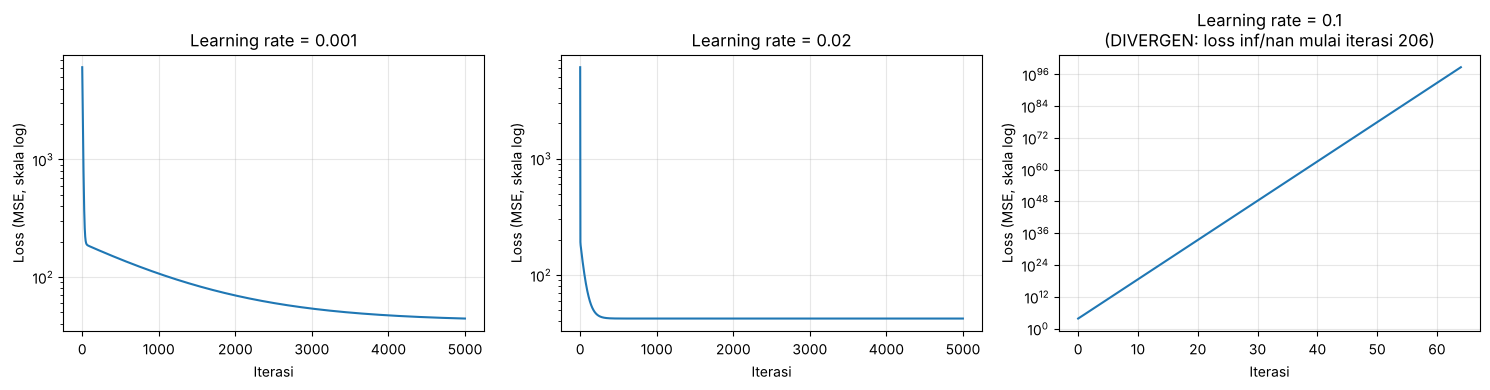

In [ ]:
# Jawaban A5
class LinearRegressionGD:
    """Linear Regression dengan Gradient Descent (loss = MSE)."""
    def __init__(self, learning_rate=0.01, n_iterations=1000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.intercept_ = 0.0
        self.coef_ = None
        self.losses_ = []

    def fit(self, X, y):
        n, d = X.shape
        self.coef_ = np.zeros(d)
        self.intercept_ = 0.0
        self.losses_ = []
        for _ in range(self.n_iterations):
            y_pred = self.intercept_ + X @ self.coef_
            error = y_pred - y
            self.losses_.append(np.mean(error ** 2))          # MSE
            dw = (2 / n) * (X.T @ error)                      # gradient terhadap koefisien
            db = (2 / n) * np.sum(error)                      # gradient terhadap intercept
            self.coef_ = self.coef_ - self.learning_rate * dw
            self.intercept_ = self.intercept_ - self.learning_rate * db
        return self

    def predict(self, X):
        return self.intercept_ + X @ self.coef_

learning_rates = [0.001, 0.02, 0.1]
models_gd = {}
for lr in learning_rates:
    print(f"=== learning_rate = {lr} ===")
    model = LinearRegressionGD(learning_rate=lr, n_iterations=5000).fit(X_train, y_train)
    models_gd[lr] = model
    print(f"Intercept : {model.intercept_}")
    print(f"Koefisien : {model.coef_[0]}")
    print(f"Loss akhir: {model.losses_[-1]}")
    print()

print("Perbandingan dengan Normal Equation:")
print(f"Normal Equation -> b = {b_ne:.4f}, m = {m_ne:.4f}")
for lr, model in models_gd.items():
    print(f"GD lr={lr:<6} -> b = {model.intercept_:.4f}, m = {model.coef_[0]:.4f}")

# Grafik loss vs iterasi
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, lr in zip(axes, learning_rates):
    losses = np.array(models_gd[lr].losses_, dtype=float)
    finite = np.isfinite(losses)                     # loss yang diverge menjadi inf/nan -> tidak bisa digambar
    tampil = finite & (losses < 1e100)               # batasi nilai ekstrem agar skala log tetap terbaca
    ax.plot(np.arange(len(losses))[tampil], losses[tampil])
    ax.set_yscale('log')
    judul = f'Learning rate = {lr}'
    if not finite.all():
        iter_gagal = int(np.argmax(~finite)) + 1
        judul += f'\n(DIVERGEN: loss inf/nan mulai iterasi {iter_gagal})'
    ax.set_title(judul)
    ax.set_xlabel('Iterasi')
    ax.set_ylabel('Loss (MSE, skala log)')
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Jawaban A5 (analisis):**

Perbandingan dengan normal equation ($b = 28.4365$, $m = 9.1358$):

| Learning rate | Intercept | Koefisien | Loss akhir | Status |
|---|---|---|---|---|
| 0.001 | 25.3493 | 9.6230 | 44.32 | **Terlalu lambat** |
| 0.02 | 28.4365 | 9.1358 | 42.22 | **Pas** |
| 0.1 | nan | nan | nan | **Divergen** |

- **lr = 0.001 (terlalu lambat).** Loss turun sangat pelan: sekitar 106.9 pada iterasi 1000, 60.1 pada iterasi 2500, dan 44.3 pada iterasi 5000, sedangkan nilai optimum 42.22. Setelah 5000 iterasi parameternya belum sampai di solusi normal equation (intercept masih 25.35, bukan 28.44). Langkah tiap iterasi terlalu kecil, sehingga butuh iterasi jauh lebih banyak.
- **lr = 0.02 (pas).** Loss turun cepat dan mendatar sebelum iterasi sekitar 500. Intercept dan koefisien akhirnya sama dengan normal equation sampai 4 desimal (28.4365 dan 9.1358), loss akhir 42.2219, sama dengan MSE training normal equation.
- **lr = 0.1 (divergen).** Loss justru membesar: 6087.9, lalu 179001.1, lalu 5.4 juta, dan seterusnya, kira-kira naik **30 kali lipat tiap iterasi**. Pada iterasi ke-206 loss melewati batas angka float64 lalu menjadi `inf` dan `nan`, sehingga intercept dan koefisien akhirnya `nan`. Pada grafik, hanya ±65 iterasi pertama yang bisa digambar karena sisanya terlalu besar.
- **Mengapa bisa terjadi?** Gradient descent berjalan menuju titik minimum loss. Jika langkahnya (learning rate) terlalu besar, langkah itu **melompati minimum** dan mendarat di sisi seberang yang lebih tinggi, sehingga kesalahan semakin besar setiap iterasi. Karena fitur `BiayaIklan` tidak distandarkan (nilainya sampai 9.9), kelengkungan loss besar sehingga batas learning rate yang aman kecil, yaitu sekitar 0.031 menurut perhitungan saya dari matriks Hessian data training. Maka 0.02 aman, sedangkan 0.1 jauh di atas batas (kesalahan dikali sekitar 5.5 tiap iterasi, loss dikali sekitar 30).
- **Arti `RuntimeWarning: overflow`.** Angka yang dihitung sudah lebih besar daripada nilai terbesar yang bisa disimpan komputer (float64, sekitar $1.8 \times 10^{308}$), sehingga hasilnya `inf`. Warning `invalid value encountered in subtract` muncul setelahnya karena `inf - inf` menghasilkan `nan`. Keduanya adalah tanda **gagal konvergen**, bukan error program.

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

Biaya iklan  4.5 juta -> prediksi penjualan = 69.55 juta
Biaya iklan  7.0 juta -> prediksi penjualan = 92.39 juta
Biaya iklan 12.0 juta -> prediksi penjualan = 138.07 juta

Rentang BiayaIklan pada data: 0.8 - 9.9 juta


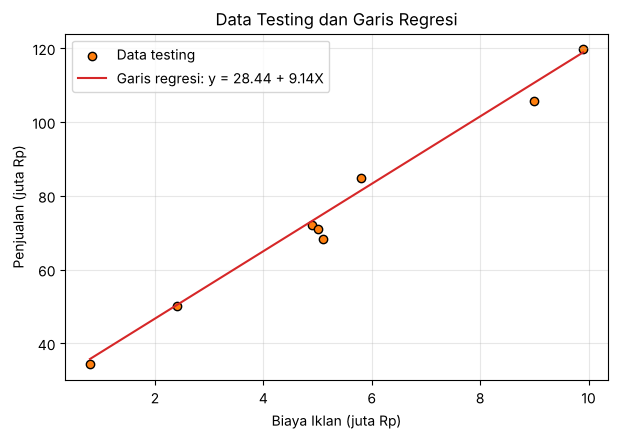

In [ ]:
# Jawaban A6
# 1. Scatter data testing + garis regresi (normal equation)
x_line = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
plt.figure(figsize=(7, 4.5))
plt.scatter(X_test, y_test, color='tab:orange', edgecolor='k', label='Data testing')
plt.plot(x_line, lin_reg.predict(x_line), color='tab:red', label=f'Garis regresi: y = {b_ne:.2f} + {m_ne:.2f}X')
plt.title('Data Testing dan Garis Regresi')
plt.xlabel('Biaya Iklan (juta Rp)')
plt.ylabel('Penjualan (juta Rp)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# 2. Prediksi
biaya_baru = np.array([[4.5], [7.0], [12.0]])
pred_baru = lin_reg.predict(biaya_baru)
for biaya, pred in zip(biaya_baru.ravel(), pred_baru):
    print(f"Biaya iklan {biaya:>4} juta -> prediksi penjualan = {pred:.2f} juta")
print(f"\nRentang BiayaIklan pada data: {X.min()} - {X.max()} juta")

**Jawaban A6 (analisis):**

Prediksi dengan model normal equation ($\hat{y} = 28.4365 + 9.1358X$):

| Biaya iklan | Prediksi penjualan |
|---|---|
| 4.5 juta | 69.55 juta |
| 7 juta | 92.39 juta |
| 12 juta | 138.07 juta |

Prediksi 4.5 juta dan 7 juta berada di dalam rentang data (0.8 sampai 9.9 juta), sehingga cukup bisa dipercaya. Kesalahan wajarnya sekitar RMSE, yaitu 3.4 sampai 6.5 juta.

Prediksi untuk **12 juta (138.07 juta) kurang bisa dipercaya** karena merupakan **ekstrapolasi**: 12 juta berada di luar data terbesar kita (9.9 juta), dan model tidak pernah melihat data di sana. Model hanya terus melanjutkan garis lurus, padahal di dunia nyata efek iklan biasanya **menurun** (diminishing returns) karena pasar mulai jenuh. Bisa saja penjualan sebenarnya jauh di bawah 138 juta. Hasil ini sebaiknya hanya dianggap perkiraan kasar, dan perlu data nyata pada biaya iklan setinggi itu sebelum dipakai untuk mengambil keputusan.

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

5 data pertama:
   JumlahLink  KataPromo  Spam
0           0          0     0
1           2          4     0
2           6          7     1
3          10          8     1
4           8          7     1

Jumlah baris data: 60

Jumlah per kelas:
Spam (1)       : 25
Bukan Spam (0) : 35

Shape X: (60, 2) | Shape y: (60,)


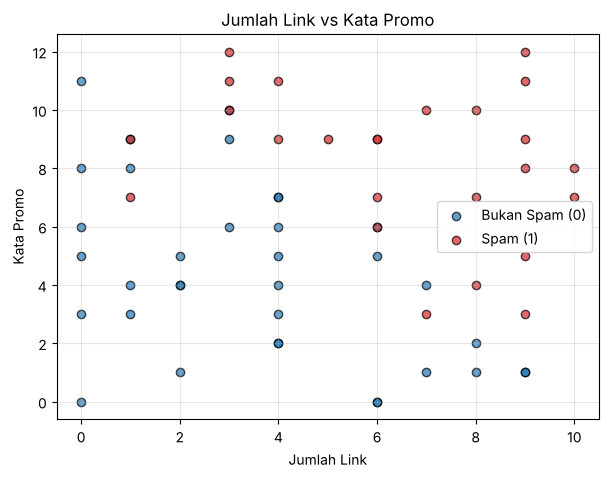

In [ ]:
# Jawaban B1
# 1. Baca data
df_email = pd.read_csv('Email_Data.csv')
print("5 data pertama:")
print(df_email.head().to_string())
print("\nJumlah baris data:", len(df_email))
print("\nJumlah per kelas:")
print("Spam (1)       :", int((df_email['Spam'] == 1).sum()))
print("Bukan Spam (0) :", int((df_email['Spam'] == 0).sum()))

# 2. Pisahkan X dan y
X_email = df_email[['JumlahLink', 'KataPromo']].values
y_email = df_email['Spam'].values
print("\nShape X:", X_email.shape, "| Shape y:", y_email.shape)

# 3. Scatter plot per kelas
plt.figure(figsize=(7, 5))
plt.scatter(X_email[y_email == 0, 0], X_email[y_email == 0, 1], color='tab:blue', edgecolor='k', alpha=0.7, label='Bukan Spam (0)')
plt.scatter(X_email[y_email == 1, 0], X_email[y_email == 1, 1], color='tab:red', edgecolor='k', alpha=0.7, label='Spam (1)')
plt.title('Jumlah Link vs Kata Promo')
plt.xlabel('Jumlah Link')
plt.ylabel('Kata Promo')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

Xe_train: (45, 2) | Xe_test: (15, 2)
Spam di train: 20 dari 45 | Spam di test: 5 dari 15

Intercept (b)        : -11.8874
Koefisien m1 (Link)  : 1.0296
Koefisien m2 (Promo) : 0.9921
P(Spam) = sigmoid(-11.8874 + 1.0296 * JumlahLink + 0.9921 * KataPromo)

Loss awal (iterasi 1)    : 0.6931
Loss iterasi ke-1000     : 0.3069
Loss iterasi ke-5000     : 0.2413
Loss akhir (iterasi 10000): 0.2338


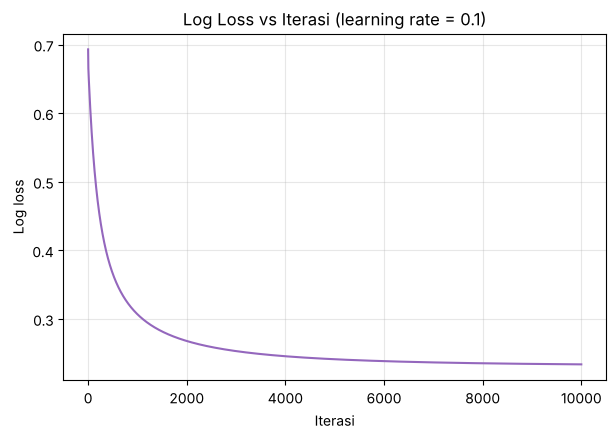

In [ ]:
# Jawaban B2
# 1. Split data
Xe_train, Xe_test, ye_train, ye_test = train_test_split(X_email, y_email, test_size=0.25, random_state=RANDOM_STATE)
print("Xe_train:", Xe_train.shape, "| Xe_test:", Xe_test.shape)
print("Spam di train:", int(ye_train.sum()), "dari", len(ye_train), "| Spam di test:", int(ye_test.sum()), "dari", len(ye_test))

# 2. Model Logistic Regression (gradient descent)
def sigmoid(z):
    z = np.clip(z, -500, 500)            # hindari overflow pada exp
    return 1 / (1 + np.exp(-z))

class LogisticRegression:
    """Logistic Regression dengan Gradient Descent (loss = log loss / binary cross-entropy)."""
    def __init__(self, learning_rate=0.1, n_iterations=1000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.intercept_ = 0.0
        self.coef_ = None
        self.losses_ = []

    def fit(self, X, y):
        n, d = X.shape
        self.coef_ = np.zeros(d)
        self.intercept_ = 0.0
        self.losses_ = []
        eps = 1e-15
        for _ in range(self.n_iterations):
            p = sigmoid(self.intercept_ + X @ self.coef_)
            loss = -np.mean(y * np.log(p + eps) + (1 - y) * np.log(1 - p + eps))
            self.losses_.append(loss)
            dw = (X.T @ (p - y)) / n
            db = np.mean(p - y)
            self.coef_ = self.coef_ - self.learning_rate * dw
            self.intercept_ = self.intercept_ - self.learning_rate * db
        return self

    def predict_proba(self, X):
        return sigmoid(self.intercept_ + X @ self.coef_)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

log_reg = LogisticRegression(learning_rate=0.1, n_iterations=10000).fit(Xe_train, ye_train)
b_lr = log_reg.intercept_
m1_lr, m2_lr = log_reg.coef_
print(f"\nIntercept (b)        : {b_lr:.4f}")
print(f"Koefisien m1 (Link)  : {m1_lr:.4f}")
print(f"Koefisien m2 (Promo) : {m2_lr:.4f}")
print(f"P(Spam) = sigmoid({b_lr:.4f} + {m1_lr:.4f} * JumlahLink + {m2_lr:.4f} * KataPromo)")
print(f"\nLoss awal (iterasi 1)    : {log_reg.losses_[0]:.4f}")
print(f"Loss iterasi ke-1000     : {log_reg.losses_[999]:.4f}")
print(f"Loss iterasi ke-5000     : {log_reg.losses_[4999]:.4f}")
print(f"Loss akhir (iterasi 10000): {log_reg.losses_[-1]:.4f}")

# 4. Grafik log loss vs iterasi
plt.figure(figsize=(7, 4.5))
plt.plot(log_reg.losses_, color='tab:purple')
plt.title('Log Loss vs Iterasi (learning rate = 0.1)')
plt.xlabel('Iterasi')
plt.ylabel('Log loss')
plt.grid(alpha=0.3)
plt.show()

**Jawaban B2 (analisis):**

Persamaan model:

$$P(\text{Spam}) = \sigma(-11.8874 + 1.0296 \cdot \text{JumlahLink} + 0.9921 \cdot \text{KataPromo})$$

Kedua koefisien positif, artinya makin banyak link dan makin banyak kata promosi, makin besar peluang email dianggap spam. Keduanya hampir sama besar (1.03 dan 0.99), jadi keduanya punya pengaruh yang kurang lebih sama.

**Log loss:** turun tajam dari 0.6931 (awal, sama dengan $\ln 2$ karena semua prediksi masih 0.5) menjadi 0.3069 pada iterasi 1000, 0.2413 pada iterasi 5000, dan 0.2338 pada iterasi 10000. Jadi loss **sudah turun dan hampir stabil**. Penurunannya masih sangat kecil (sekitar 0.007 antara iterasi 5000 dan 10000), yang berarti model hampir konvergen tetapi belum sepenuhnya datar. Hal ini akan dibahas lagi pada soal bonus.

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [ ]:
# Jawaban B3
def accuracy_score(y_true, y_pred):
    return np.mean(y_true == y_pred)

def confusion_matrix(y_true, y_pred):
    """Mengembalikan [[TN, FP], [FN, TP]]"""
    tn = int(np.sum((y_true == 0) & (y_pred == 0)))
    fp = int(np.sum((y_true == 0) & (y_pred == 1)))
    fn = int(np.sum((y_true == 1) & (y_pred == 0)))
    tp = int(np.sum((y_true == 1) & (y_pred == 1)))
    return np.array([[tn, fp], [fn, tp]])

def precision_score(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    tp, fp = cm[1, 1], cm[0, 1]
    return tp / (tp + fp) if (tp + fp) > 0 else 0.0

def recall_score(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    tp, fn = cm[1, 1], cm[1, 0]
    return tp / (tp + fn) if (tp + fn) > 0 else 0.0

def f1_score(y_true, y_pred):
    p = precision_score(y_true, y_pred)
    r = recall_score(y_true, y_pred)
    return 2 * p * r / (p + r) if (p + r) > 0 else 0.0

ye_pred = log_reg.predict(Xe_test)               # threshold default 0.5
cm = confusion_matrix(ye_test, ye_pred)
print("Evaluasi pada DATA TESTING (threshold 0.5)")
print(f"Accuracy  : {accuracy_score(ye_test, ye_pred):.4f}")
print(f"Precision : {precision_score(ye_test, ye_pred):.4f}")
print(f"Recall    : {recall_score(ye_test, ye_pred):.4f}")
print(f"F1-score  : {f1_score(ye_test, ye_pred):.4f}")
print("\nConfusion matrix:")
print(pd.DataFrame(cm, index=['Aktual Bukan Spam', 'Aktual Spam'], columns=['Prediksi Bukan Spam', 'Prediksi Spam']).to_string())
print(f"\nTN={cm[0,0]}, FP={cm[0,1]}, FN={cm[1,0]}, TP={cm[1,1]}")
print("Accuracy pada data training (pembanding):", round(accuracy_score(ye_train, log_reg.predict(Xe_train)), 4))

Evaluasi pada DATA TESTING (threshold 0.5)
Accuracy  : 0.8667
Precision : 0.8000
Recall    : 0.8000
F1-score  : 0.8000

Confusion matrix:
                   Prediksi Bukan Spam  Prediksi Spam
Aktual Bukan Spam                    9              1
Aktual Spam                          1              4

TN=9, FP=1, FN=1, TP=4
Accuracy pada data training (pembanding): 0.9111


**Jawaban B3 (analisis):**

Pada data testing (15 email, threshold 0.5): accuracy **0.8667**, precision **0.80**, recall **0.80**, F1 **0.80**. Confusion matrix: TN = 9, FP = 1, FN = 1, TP = 4. Accuracy pada training adalah 0.9111, selisihnya kecil sehingga tidak ada tanda overfitting yang berat.

- **FP (false positive):** email yang sebenarnya **bukan spam** tetapi diprediksi **spam**. Email penting masuk ke folder spam atau terhapus.
- **FN (false negative):** email yang sebenarnya **spam** tetapi lolos diprediksi **bukan spam**. Spam masuk ke inbox.

Menurut saya **FP lebih merugikan pengguna**. Pengguna bisa melewatkan email penting (misalnya undangan wawancara, tagihan, atau informasi kuliah) tanpa menyadarinya, dan kerugiannya bisa besar. Sebaliknya FN hanya membuat pengguna melihat satu email sampah, yang mengganggu tetapi mudah dihapus sendiri.

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

Decision boundary: x2 = -(-11.8874 + 1.0296 * x1) / 0.9921
               atau x2 = 11.9818 + (-1.0378) * x1

Jumlah data testing yang salah diklasifikasikan: 2 dari 15
 JumlahLink  KataPromo  Aktual  Prediksi  P(Spam)
          6          6       0         1   0.5605
          1          7       1         0   0.0196


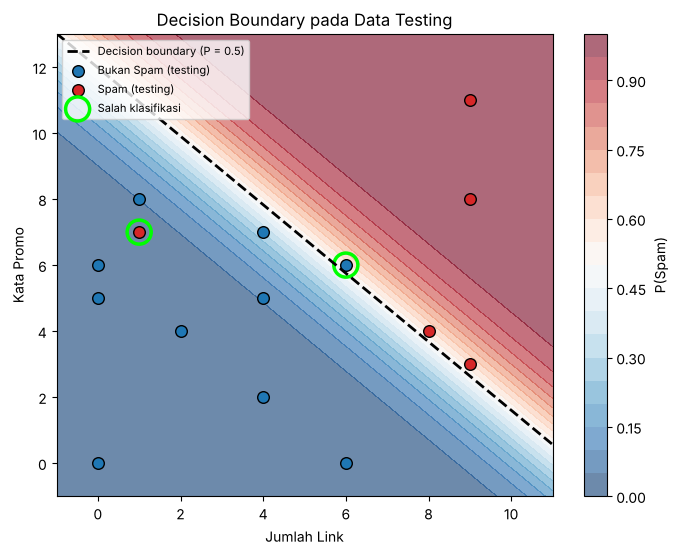

In [ ]:
# Jawaban B4
# 1. Persamaan decision boundary: x2 = -(b + m1*x1) / m2
print(f"Decision boundary: x2 = -({b_lr:.4f} + {m1_lr:.4f} * x1) / {m2_lr:.4f}")
print(f"               atau x2 = {-b_lr / m2_lr:.4f} + ({-m1_lr / m2_lr:.4f}) * x1")

# 2. Visualisasi
x1_min, x1_max = X_email[:, 0].min() - 1, X_email[:, 0].max() + 1
x2_min, x2_max = X_email[:, 1].min() - 1, X_email[:, 1].max() + 1
xx1, xx2 = np.meshgrid(np.linspace(x1_min, x1_max, 300), np.linspace(x2_min, x2_max, 300))
grid = np.c_[xx1.ravel(), xx2.ravel()]
prob_grid = log_reg.predict_proba(grid).reshape(xx1.shape)

x1_line = np.linspace(x1_min, x1_max, 100)
x2_line = -(b_lr + m1_lr * x1_line) / m2_lr

salah = ye_pred != ye_test
plt.figure(figsize=(8, 6))
cs = plt.contourf(xx1, xx2, prob_grid, levels=20, cmap='RdBu_r', alpha=0.6)
plt.colorbar(cs, label='P(Spam)')
plt.plot(x1_line, x2_line, 'k--', linewidth=2, label='Decision boundary (P = 0.5)')
plt.scatter(Xe_test[(ye_test == 0), 0], Xe_test[(ye_test == 0), 1], color='tab:blue', edgecolor='k', s=70, label='Bukan Spam (testing)')
plt.scatter(Xe_test[(ye_test == 1), 0], Xe_test[(ye_test == 1), 1], color='tab:red', edgecolor='k', s=70, label='Spam (testing)')
plt.scatter(Xe_test[salah, 0], Xe_test[salah, 1], facecolors='none', edgecolors='lime', s=300, linewidths=2.5, label='Salah klasifikasi')
plt.xlim(x1_min, x1_max)
plt.ylim(x2_min, x2_max)
plt.title('Decision Boundary pada Data Testing')
plt.xlabel('Jumlah Link')
plt.ylabel('Kata Promo')
plt.legend(loc='upper left', fontsize=8)
plt.show()

# 3. Data yang salah diklasifikasikan
salah_df = pd.DataFrame({
    'JumlahLink': Xe_test[salah, 0],
    'KataPromo': Xe_test[salah, 1],
    'Aktual': ye_test[salah],
    'Prediksi': ye_pred[salah],
    'P(Spam)': log_reg.predict_proba(Xe_test[salah]).round(4),
})
print(f"\nJumlah data testing yang salah diklasifikasikan: {int(salah.sum())} dari {len(ye_test)}")
print(salah_df.to_string(index=False))

**Jawaban B4 (analisis):**

Decision boundary: $x_2 = -\dfrac{-11.8874 + 1.0296\,x_1}{0.9921} = 11.9818 - 1.0378\,x_1$.

Karena $m_1 \approx m_2 \approx 1$, garisnya hampir sama dengan $\text{JumlahLink} + \text{KataPromo} \approx 12$. Aturan praktisnya: email cenderung dianggap spam jika jumlah link ditambah jumlah kata promosinya sekitar 12 atau lebih. Pada gambar, daerah merah (probabilitas spam tinggi) ada di kanan atas garis dan daerah biru di kiri bawah.

Data testing yang **salah diklasifikasikan** ada **2 dari 15** (ditandai lingkaran hijau):

1. **(Link = 6, Promo = 6)**, aslinya **bukan spam** tetapi diprediksi spam (FP) dengan P(Spam) = 0.5605. Titik ini tepat berada di dekat garis (6 + 6 = 12), jadi wajar sulit dibedakan.
2. **(Link = 1, Promo = 7)**, aslinya **spam** tetapi diprediksi bukan spam (FN) dengan P(Spam) = 0.0196. Titik ini jauh di sisi biru, sehingga model sangat yakin tetapi salah. Titik seperti ini kemungkinan kasus langka (spam dengan sedikit link) yang tidak bisa ditangkap oleh garis lurus.

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [ ]:
# Jawaban B5
proba_test = log_reg.predict_proba(Xe_test)
baris = []
for th in [0.3, 0.5, 0.7]:
    pred = (proba_test >= th).astype(int)
    cm_th = confusion_matrix(ye_test, pred)
    baris.append({
        'Threshold': th,
        'TN': cm_th[0, 0], 'FP': cm_th[0, 1], 'FN': cm_th[1, 0], 'TP': cm_th[1, 1],
        'Precision': precision_score(ye_test, pred),
        'Recall': recall_score(ye_test, pred),
        'Accuracy': accuracy_score(ye_test, pred),
    })
tabel_th = pd.DataFrame(baris).set_index('Threshold')
print(tabel_th.round(4).to_string())

           TN  FP  FN  TP  Precision  Recall  Accuracy
Threshold                                             
0.3         8   2   1   4     0.6667     0.8    0.8000
0.5         9   1   1   4     0.8000     0.8    0.8667
0.7        10   0   3   2     1.0000     0.4    0.8000


**Jawaban B5 (analisis):**

| Threshold | TN | FP | FN | TP | Precision | Recall |
|---|---|---|---|---|---|---|
| 0.3 | 8 | 2 | 1 | 4 | 0.6667 | 0.80 |
| 0.5 | 9 | 1 | 1 | 4 | 0.8000 | 0.80 |
| 0.7 | 10 | 0 | 3 | 2 | 1.0000 | 0.40 |

**Pengaruh threshold:**
- **Threshold dinaikkan** (0.5 ke 0.7): model lebih "pelit" melabeli spam, sehingga FP turun (1 ke 0) dan precision naik (0.80 ke 1.00), tetapi FN naik (1 ke 3) dan recall turun drastis (0.80 ke 0.40).
- **Threshold diturunkan** (0.5 ke 0.3): model lebih "mudah curiga", sehingga recall tetap 0.80 pada data ini tetapi FP naik (1 ke 2) dan precision turun (0.80 ke 0.67).

Ada *trade-off*: precision dan recall tidak bisa dinaikkan bersamaan hanya dengan mengubah threshold.

**Threshold pilihan saya: 0.5.** Berdasarkan B3, FP lebih merugikan, sehingga menaikkan threshold menarik. Tetapi pada 0.7 model hanya menangkap 2 dari 5 spam (recall 0.40), jadi filter hampir tidak berfungsi. Threshold 0.5 memberi akurasi tertinggi (0.8667) dengan FP hanya 1. Catatan: data testing hanya 15 email, jadi selisih satu email sudah mengubah angka cukup besar. Jika layanan ini dipakai untuk email yang sangat penting (misalnya email kantor), threshold sedikit di atas 0.5 (misalnya 0.6) bisa dipertimbangkan, dengan konsekuensi lebih banyak spam yang lolos.

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [ ]:
# Jawaban B6
THRESHOLD_PILIHAN = 0.5   # threshold pilihan dari Soal B5

email_baru = pd.DataFrame({
    'Email': ['E1', 'E2', 'E3', 'E4'],
    'JumlahLink': [1, 5, 9, 2],
    'KataPromo': [2, 6, 10, 11],
})
proba_baru = log_reg.predict_proba(email_baru[['JumlahLink', 'KataPromo']].values)
email_baru['P(Spam)'] = proba_baru.round(4)
email_baru['Prediksi'] = np.where(proba_baru >= THRESHOLD_PILIHAN, 'Spam', 'Bukan Spam')
print(f"Threshold yang dipakai: {THRESHOLD_PILIHAN}")
print(email_baru.to_string(index=False))

Threshold yang dipakai: 0.5
Email  JumlahLink  KataPromo  P(Spam)   Prediksi
   E1           1          2   0.0001 Bukan Spam
   E2           5          6   0.3129 Bukan Spam
   E3           9         10   0.9993       Spam
   E4           2         11   0.7475       Spam


---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:** Logistic Regression termasuk klasifikasi karena **outputnya adalah kelas** (misalnya Spam atau Bukan Spam), bukan nilai kontinu. Namanya "regression" karena di dalamnya ada persamaan linear $z = b + m_1x_1 + m_2x_2$ seperti pada regresi. Fungsi **sigmoid** $\sigma(z) = \frac{1}{1+e^{-z}}$ mengubah $z$ (yang bisa bernilai berapa saja) menjadi angka antara 0 dan 1 yang dibaca sebagai **probabilitas** kelas positif. Setelah itu, probabilitas dibandingkan dengan threshold (default 0.5) untuk menentukan kelasnya.

**Jawaban C2:** **Normal equation** menghitung parameter langsung dalam sekali hitung memakai rumus $\theta = (X^TX)^{-1}X^Ty$, tanpa learning rate dan tanpa iterasi. **Gradient descent** mencari parameter secara bertahap: tiap iterasi menghitung gradient dan menggeser parameter ke arah yang menurunkan loss, sehingga butuh learning rate dan jumlah iterasi yang dipilih dengan benar (seperti terlihat pada A5). Gradient descent sebaiknya dipakai ketika **fitur atau datanya sangat banyak** (karena membalik matriks $X^TX$ mahal), atau ketika model tidak punya rumus langsung, seperti Logistic Regression.

**Jawaban C3:** Model dievaluasi pada **data testing** karena data tersebut tidak dipakai saat training, sehingga hasilnya menggambarkan kemampuan model pada **data baru**. Jika dievaluasi pada data training, nilainya bisa terlihat bagus padahal model hanya menghafal data itu. **Overfitting** adalah kondisi saat model sangat bagus pada data training tetapi buruk pada data testing, karena ia ikut mempelajari noise dan bukan pola umumnya. Pada tugas ini, accuracy training (0.9111) dan testing (0.8667) pada Logistic Regression selisihnya kecil, jadi tidak terlihat overfitting yang berarti.

**Jawaban C4:** Linear Regression memprediksi **angka kontinu**, sehingga cocok diukur dengan **MSE**, yaitu rata-rata kuadrat selisih angka prediksi dan angka sebenarnya. Logistic Regression memprediksi **probabilitas** antara 0 dan 1 untuk label 0 atau 1. Untuk itu dipakai **log loss** $-[y\ln p + (1-y)\ln(1-p)]$, yang memberi hukuman sangat besar jika model yakin tetapi salah (misalnya $p$ mendekati 0 padahal kelas sebenarnya 1). Selain itu, jika MSE dipakai dengan sigmoid, fungsi loss-nya tidak cembung sehingga gradient descent bisa tersangkut, sedangkan log loss tetap cembung.

**Jawaban C5:** Angka hasil bisa berbeda karena **pembagian data train dan test bergantung pada `random_state`**, yang diambil dari 2 digit terakhir NIM masing-masing. Dengan `random_state` berbeda, isi data training dan testing berbeda, sehingga koefisien, RMSE, R², accuracy, dan confusion matrix ikut berbeda. Perbedaan ini terasa besar karena datanya kecil (40 dan 60 baris), jadi satu atau dua titik yang pindah ke data testing sudah mengubah angkanya. Perbedaan juga bisa muncul dari pilihan lain seperti learning rate, jumlah iterasi, dan threshold.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [ ]:
# Jawaban Bonus
from sklearn.linear_model import LinearRegression as SkLinearRegression
from sklearn.linear_model import LogisticRegression as SkLogisticRegression

# --- Linear Regression ---
sk_lin = SkLinearRegression().fit(X_train, y_train)
print("LINEAR REGRESSION")
print(f"Implementasi sendiri : b = {b_ne:.4f}, m = {m_ne:.4f}")
print(f"scikit-learn         : b = {sk_lin.intercept_:.4f}, m = {sk_lin.coef_[0]:.4f}")
print(f"R2 testing sendiri = {r2_score(y_test, y_pred_test):.4f} | sklearn = {r2_score(y_test, sk_lin.predict(X_test)):.4f}")

# --- Logistic Regression ---
sk_log_default = SkLogisticRegression().fit(Xe_train, ye_train)                 # default: penalty L2, C=1.0
sk_log_nopen = SkLogisticRegression(C=1e10, max_iter=10000).fit(Xe_train, ye_train)  # regularisasi hampir dimatikan

def ringkas(nama, b, m, pred):
    return {'Model': nama, 'b': b, 'm1 (Link)': m[0], 'm2 (Promo)': m[1],
            'Accuracy': accuracy_score(ye_test, pred),
            'Precision': precision_score(ye_test, pred),
            'Recall': recall_score(ye_test, pred),
            'F1': f1_score(ye_test, pred)}

tabel_bonus = pd.DataFrame([
    ringkas('Sendiri (GD, tanpa regularisasi)', b_lr, log_reg.coef_, log_reg.predict(Xe_test)),
    ringkas('sklearn default (L2, C=1)', sk_log_default.intercept_[0], sk_log_default.coef_[0], sk_log_default.predict(Xe_test)),
    ringkas('sklearn C=1e10 (tanpa regularisasi)', sk_log_nopen.intercept_[0], sk_log_nopen.coef_[0], sk_log_nopen.predict(Xe_test)),
]).set_index('Model')
print("\nLOGISTIC REGRESSION")
print(tabel_bonus.round(4).to_string())

LINEAR REGRESSION
Implementasi sendiri : b = 28.4365, m = 9.1358
scikit-learn         : b = 28.4365, m = 9.1358
R2 testing sendiri = 0.9823 | sklearn = 0.9823

LOGISTIC REGRESSION
                                           b  m1 (Link)  m2 (Promo)  Accuracy  Precision  Recall   F1
Model                                                                                                
Sendiri (GD, tanpa regularisasi)    -11.8874     1.0296      0.9921    0.8667        0.8     0.8  0.8
sklearn default (L2, C=1)           -11.1592     0.9531      0.9351    0.8667        0.8     0.8  0.8
sklearn C=1e10 (tanpa regularisasi) -13.7514     1.2078      1.1356    0.8667        0.8     0.8  0.8


**Jawaban Bonus (analisis):**

**Linear Regression:** hasil scikit-learn **sama persis** dengan implementasi saya ($b = 28.4365$, $m = 9.1358$, R² testing = 0.9823), karena keduanya menyelesaikan masalah kuadrat terkecil secara eksak lewat normal equation, sehingga tidak ada perbedaan yang perlu dijelaskan.

**Logistic Regression:** koefisien berbeda, tetapi **evaluasi pada data testing sama** (accuracy 0.8667, precision 0.80, recall 0.80, F1 0.80). Ada dua penyebab perbedaan koefisien:

1. **Regularisasi.** `LogisticRegression` scikit-learn secara default memakai `penalty='l2'` dengan `C=1.0`. Regularisasi ini menjaga bobot tetap kecil, sehingga koefisiennya lebih kecil ($b = -11.1592$, $m_1 = 0.9531$, $m_2 = 0.9351$) dibanding implementasi saya yang tidak memakai regularisasi ($b = -11.8874$, $m_1 = 1.0296$, $m_2 = 0.9921$).
2. **Konvergensi.** Saat regularisasi hampir dimatikan (`C=1e10`), scikit-learn menghasilkan bobot yang **lebih besar** ($b = -13.7514$, $m_1 = 1.2078$, $m_2 = 1.1356$) dan log loss training yang sedikit lebih rendah (0.2317 dibanding 0.2338 milik saya). Artinya gradient descent saya dengan 10000 iterasi **belum sepenuhnya sampai di titik optimum**: loss masih bisa turun sedikit lagi jika iterasi ditambah. Ini sesuai dengan pengamatan di B2 bahwa loss masih turun sedikit di akhir.

Meski koefisiennya berbeda, **decision boundary-nya hampir sama** (perbandingan $m_1 : m_2$ dan posisi garisnya mirip), sehingga prediksi kelas pada data testing identik. Perbedaan koefisien terutama memengaruhi seberapa yakin (ekstrem) probabilitasnya, bukan kelas akhirnya.